In [ ]:
from google.colab import files

uploaded = files.upload()

Saving UNSW_NB15_training-set.csv to UNSW_NB15_training-set (1).csv


In [ ]:

import pandas as pd

df = pd.read_csv('/content/UNSW_NB15_training-set.csv')

print("Dataset loaded successfully!")
print("Shape:", df.shape)

df.head()


Dataset loaded successfully!
Shape: (175341, 45)


,id,dur,proto,service,state,spkts,dpkts,sbytes,dbytes,rate,...,ct_dst_sport_ltm,ct_dst_src_ltm,is_ftp_login,ct_ftp_cmd,ct_flw_http_mthd,ct_src_ltm,ct_srv_dst,is_sm_ips_ports,attack_cat,label
0,1,0.121478,tcp,-,FIN,6,4,258,172,74.087490,...,1,1,0,0,0,1,1,0,Normal,0
1,2,0.649902,tcp,-,FIN,14,38,734,42014,78.473372,...,1,2,0,0,0,1,6,0,Normal,0
2,3,1.623129,tcp,-,FIN,8,16,364,13186,14.170161,...,1,3,0,0,0,2,6,0,Normal,0
3,4,1.681642,tcp,ftp,FIN,12,12,628,770,13.677108,...,1,3,1,1,0,2,1,0,Normal,0
4,5,0.449454,tcp,-,FIN,10,6,534,268,33.373826,...,1,40,0,0,0,2,39,0,Normal,0


In [ ]:

# 1. Check all column names
print("Column names:")
print(df.columns.tolist())

# 2. Check data types and missing values
print("\nDataset information:")
df.info()

# 3. Check missing values in each column
print("\nMissing values:")
print(df.isnull().sum().sort_values(ascending=False).head(15))

# 4. Check the target labels
print("\nAttack categories:")
print(df['attack_cat'].value_counts(dropna=False))

print("\nBinary labels:")
print(df['label'].value_counts(dropna=False))


Column names:
['id', 'dur', 'proto', 'service', 'state', 'spkts', 'dpkts', 'sbytes', 'dbytes', 'rate', 'sttl', 'dttl', 'sload', 'dload', 'sloss', 'dloss', 'sinpkt', 'dinpkt', 'sjit', 'djit', 'swin', 'stcpb', 'dtcpb', 'dwin', 'tcprtt', 'synack', 'ackdat', 'smean', 'dmean', 'trans_depth', 'response_body_len', 'ct_srv_src', 'ct_state_ttl', 'ct_dst_ltm', 'ct_src_dport_ltm', 'ct_dst_sport_ltm', 'ct_dst_src_ltm', 'is_ftp_login', 'ct_ftp_cmd', 'ct_flw_http_mthd', 'ct_src_ltm', 'ct_srv_dst', 'is_sm_ips_ports', 'attack_cat', 'label']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 175341 entries, 0 to 175340
Data columns (total 45 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   id                 175341 non-null  int64  
 1   dur                175341 non-null  float64
 2   proto              175341 non-null  object 
 3   service            175341 non-null  object 
 4   state              175341 non-null  o

In [ ]:

# 1. Check duplicate rows
print("Duplicate rows:", df.duplicated().sum())

# 2. Check unique values in categorical columns
for col in ['proto', 'service', 'state', 'attack_cat']:
    print(f"\n{col}:")
    print(df[col].value_counts().head(15))

# 3. Check whether any numeric columns contain infinite values
import numpy as np

numeric_df = df.select_dtypes(include='number')
print("\nInfinite values:", np.isinf(numeric_df).sum().sum())

# 4. Check whether the ID column is unique
print("\nUnique IDs:", df['id'].nunique())
print("Total rows:", len(df))


Duplicate rows: 0

proto:
proto
tcp       79946
udp       63283
unas      12084
arp        2859
ospf       2595
sctp       1150
any         300
gre         225
ipv6        201
mobile      201
pim         201
swipe       201
sun-nd      201
rsvp        200
sep         193
Name: count, dtype: int64

service:
service
-           94168
dns         47294
http        18724
smtp         5058
ftp-data     3995
ftp          3428
ssh          1302
pop3         1105
dhcp           94
snmp           80
ssl            56
irc            25
radius         12
Name: count, dtype: int64

state:
state
INT    82275
FIN    77825
CON    13152
REQ     1991
RST       83
ECO       12
PAR        1
URN        1
no         1
Name: count, dtype: int64

attack_cat:
attack_cat
Normal            56000
Generic           40000
Exploits          33393
Fuzzers           18184
DoS               12264
Reconnaissance    10491
Analysis           2000
Backdoor           1746
Shellcode          1133
Worms               130
Nam

In [ ]:

# Separate target from input features
y = df['attack_cat']

# Remove target columns and ID from input features
X = df.drop(columns=['id', 'attack_cat', 'label'])

print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nFeature data types:")
print(X.dtypes.value_counts())

print("\nTarget classes:")
print(y.unique())


Features shape: (175341, 42)
Target shape: (175341,)

Feature data types:
int64      28
float64    11
object      3
Name: count, dtype: int64

Target classes:
['Normal' 'Backdoor' 'Analysis' 'Fuzzers' 'Shellcode' 'Reconnaissance'
 'Exploits' 'DoS' 'Worms' 'Generic']


In [ ]:

from sklearn.model_selection import train_test_split

X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Validation features:", X_val.shape)

print("\nTraining class distribution:")
print(y_train.value_counts())


Training features: (140272, 42)
Validation features: (35069, 42)

Training class distribution:
attack_cat
Normal            44800
Generic           32000
Exploits          26714
Fuzzers           14547
DoS                9811
Reconnaissance     8393
Analysis           1600
Backdoor           1397
Shellcode           906
Worms               104
Name: count, dtype: int64


In [ ]:

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline

# Identify numerical and categorical columns
categorical_cols = X.select_dtypes(include=['object']).columns.tolist()
numerical_cols = X.select_dtypes(exclude=['object']).columns.tolist()

# Preprocess each type of feature differently
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_cols)
    ]
)

print("Numerical columns:", numerical_cols)
print("Categorical columns:", categorical_cols)


Numerical columns: ['dur', 'spkts', 'dpkts', 'sbytes', 'dbytes', 'rate', 'sttl', 'dttl', 'sload', 'dload', 'sloss', 'dloss', 'sinpkt', 'dinpkt', 'sjit', 'djit', 'swin', 'stcpb', 'dtcpb', 'dwin', 'tcprtt', 'synack', 'ackdat', 'smean', 'dmean', 'trans_depth', 'response_body_len', 'ct_srv_src', 'ct_state_ttl', 'ct_dst_ltm', 'ct_src_dport_ltm', 'ct_dst_sport_ltm', 'ct_dst_src_ltm', 'is_ftp_login', 'ct_ftp_cmd', 'ct_flw_http_mthd', 'ct_src_ltm', 'ct_srv_dst', 'is_sm_ips_ports']
Categorical columns: ['proto', 'service', 'state']


In [ ]:

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix

model = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(
        max_iter=1000,
        class_weight='balanced',
        random_state=42
    ))
])

# Train the model
model.fit(X_train, y_train)

# Predict validation labels
y_pred = model.predict(X_val)

# Evaluate
print("Validation Accuracy:", accuracy_score(y_val, y_pred))

print("\nClassification Report:")
print(classification_report(y_val, y_pred, zero_division=0))


# Generate confusion matrix
cm = confusion_matrix(y_val, y_pred, labels=model.classes_)

print("Confusion Matrix:")
print(cm)


Validation Accuracy: 0.6717328694858707

Classification Report:
                precision    recall  f1-score   support

      Analysis       0.08      0.46      0.14       400
      Backdoor       0.04      0.23      0.06       349
           DoS       0.31      0.27      0.29      2453
      Exploits       0.85      0.38      0.52      6679
       Fuzzers       0.57      0.68      0.62      3637
       Generic       1.00      0.98      0.99      8000
        Normal       0.99      0.80      0.89     11200
Reconnaissance       0.48      0.28      0.35      2098
     Shellcode       0.10      0.84      0.18       227
         Worms       0.02      0.96      0.04        26

      accuracy                           0.67     35069
     macro avg       0.44      0.59      0.41     35069
  weighted avg       0.82      0.67      0.72     35069

Confusion Matrix:
[[ 184   95  113    7    0    0    0    1    0    0]
 [  98   79  118    8    4    0    2   22    7   11]
 [ 645  677  660  245   4

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Preprocessing: no scaling needed for Random Forest
rf_preprocessor = ColumnTransformer(
    transformers=[
        ('num', 'passthrough', numerical_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_cols)
    ]
)

# Random Forest without class weights
rf_model = Pipeline([
    ('preprocessor', rf_preprocessor),
    ('classifier', RandomForestClassifier(
        n_estimators=100,
        class_weight=None,
        random_state=42,
        n_jobs=-1,
        min_samples_leaf=2
    ))
])

# Train
rf_model.fit(X_train, y_train)

print("Random Forest training completed!")

Random Forest training completed!


In [ ]:
rf_pred = rf_model.predict(X_val)

print("Validation Accuracy:", accuracy_score(y_val, rf_pred))

print("\nClassification Report:")
print(classification_report(y_val, rf_pred, zero_division=0))

print("\nConfusion Matrix:")
cm_rf = confusion_matrix(
    y_val, rf_pred,
    labels=rf_model.classes_
)
print(cm_rf)

Validation Accuracy: 0.8235193475719296

Classification Report:
                precision    recall  f1-score   support

      Analysis       0.71      0.12      0.21       400
      Backdoor       0.76      0.08      0.15       349
           DoS       0.28      0.17      0.21      2453
      Exploits       0.62      0.86      0.72      6679
       Fuzzers       0.76      0.76      0.76      3637
       Generic       1.00      0.98      0.99      8000
        Normal       0.95      0.93      0.94     11200
Reconnaissance       0.92      0.73      0.82      2098
     Shellcode       0.69      0.64      0.67       227
         Worms       1.00      0.12      0.21        26

      accuracy                           0.82     35069
     macro avg       0.77      0.54      0.57     35069
  weighted avg       0.82      0.82      0.81     35069


Confusion Matrix:
[[   50     7    60   243     0     0    40     0     0     0]
 [   12    28    62   239     4     0     0     1     3     0]
 [  

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Preprocessing: no scaling needed for Random Forest
rf_weighted_preprocessor = ColumnTransformer(
    transformers=[
        ('num', 'passthrough', numerical_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_cols)
    ]
)

# Random Forest without class weights
rf_weighted_model = Pipeline([
    ('preprocessor', rf_weighted_preprocessor),
    ('classifier', RandomForestClassifier(
        n_estimators=100,
        class_weight='balanced_subsample',
        random_state=42,
        n_jobs=-1,
        min_samples_leaf=2
    ))
])

# Train
rf_weighted_model.fit(X_train, y_train)

print("Random Forest training completed!")


rf_weighted_pred = rf_weighted_model.predict(X_val)

print("Validation Accuracy:", accuracy_score(y_val, rf_weighted_pred))

print("\nClassification Report:")
print(classification_report(y_val, rf_weighted_pred, zero_division=0))

print("\nConfusion Matrix:")
cm_rf = confusion_matrix(
    y_val, rf_weighted_pred,
    labels=rf_model.classes_
)
print(cm_rf)

Random Forest training completed!
Validation Accuracy: 0.7781516439020217

Classification Report:
                precision    recall  f1-score   support

      Analysis       0.07      0.17      0.10       400
      Backdoor       0.03      0.15      0.05       349
           DoS       0.29      0.40      0.34      2453
      Exploits       0.83      0.54      0.66      6679
       Fuzzers       0.70      0.83      0.76      3637
       Generic       1.00      0.98      0.99      8000
        Normal       0.97      0.88      0.93     11200
Reconnaissance       0.86      0.77      0.81      2098
     Shellcode       0.52      0.85      0.65       227
         Worms       0.64      0.62      0.63        26

      accuracy                           0.78     35069
     macro avg       0.59      0.62      0.59     35069
  weighted avg       0.85      0.78      0.80     35069


Confusion Matrix:
[[  67   95  191   19    0    0   28    0    0    0]
 [  47   54  215   20    2    0    0    6  

In [ ]:
!pip -q install imbalanced-learn

In [ ]:
from imblearn.under_sampling import RandomUnderSampler
from collections import Counter

# Reduce majority classes in the training data
undersampler = RandomUnderSampler(
    sampling_strategy='not minority',
    random_state=42
)

X_train_under, y_train_under = undersampler.fit_resample(
    X_train, y_train
)

print("Original training distribution:")
print(Counter(y_train))

print("\nUndersampled training distribution:")
print(Counter(y_train_under))

print("\nOriginal training shape:", X_train.shape)
print("Undersampled training shape:", X_train_under.shape)

Original training distribution:
Counter({'Normal': 44800, 'Generic': 32000, 'Exploits': 26714, 'Fuzzers': 14547, 'DoS': 9811, 'Reconnaissance': 8393, 'Analysis': 1600, 'Backdoor': 1397, 'Shellcode': 906, 'Worms': 104})

Undersampled training distribution:
Counter({'Analysis': 104, 'Backdoor': 104, 'DoS': 104, 'Exploits': 104, 'Fuzzers': 104, 'Generic': 104, 'Normal': 104, 'Reconnaissance': 104, 'Shellcode': 104, 'Worms': 104})

Original training shape: (140272, 42)
Undersampled training shape: (1040, 42)


In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

# Reuse the preprocessing approach from the earlier Random Forest
rf_under_preprocessor = ColumnTransformer(
    transformers=[
        ('num', 'passthrough', numerical_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_cols)
    ]
)

rf_under_model = Pipeline([
    ('preprocessor', rf_under_preprocessor),
    ('classifier', RandomForestClassifier(
        n_estimators=100,
        class_weight=None,
        random_state=42,
        n_jobs=-1,
        min_samples_leaf=2
    ))
])

rf_under_model.fit(X_train_under, y_train_under)

print("Undersampled Random Forest training completed!")

from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

rf_under_pred = rf_under_model.predict(X_val)

print("Validation Accuracy:",
      accuracy_score(y_val, rf_under_pred))

print("\nClassification Report:")
print(classification_report(
    y_val, rf_under_pred, zero_division=0
))

print("\nConfusion Matrix:")
print(confusion_matrix(
    y_val, rf_under_pred,
    labels=rf_under_model.classes_
))

Undersampled Random Forest training completed!
Validation Accuracy: 0.7096581025977359

Classification Report:
                precision    recall  f1-score   support

      Analysis       0.09      0.40      0.15       400
      Backdoor       0.06      0.32      0.10       349
           DoS       0.33      0.32      0.32      2453
      Exploits       0.84      0.40      0.54      6679
       Fuzzers       0.57      0.75      0.65      3637
       Generic       0.99      0.98      0.98      8000
        Normal       0.97      0.79      0.87     11200
Reconnaissance       0.74      0.73      0.73      2098
     Shellcode       0.20      0.87      0.33       227
         Worms       0.02      0.92      0.05        26

      accuracy                           0.71     35069
     macro avg       0.48      0.65      0.47     35069
  weighted avg       0.83      0.71      0.74     35069


Confusion Matrix:
[[ 159   99  124    8    0    0    1    4    3    2]
 [  53  113  124   15    5    

In [ ]:
from imblearn.under_sampling import RandomUnderSampler
from collections import Counter

# Keep up to 5,000 samples per class
undersampler_moderate = RandomUnderSampler(
    sampling_strategy={
        cls: min(count, 5000)
        for cls, count in Counter(y_train).items()
        if count > 5000
    },
    random_state=42
)

X_train_moderate, y_train_moderate = (
    undersampler_moderate.fit_resample(X_train, y_train)
)

print("Before undersampling:")
print(Counter(y_train))

print("\nAfter moderate undersampling:")
print(Counter(y_train_moderate))

print("\nNew training shape:", X_train_moderate.shape)

Before undersampling:
Counter({'Normal': 44800, 'Generic': 32000, 'Exploits': 26714, 'Fuzzers': 14547, 'DoS': 9811, 'Reconnaissance': 8393, 'Analysis': 1600, 'Backdoor': 1397, 'Shellcode': 906, 'Worms': 104})

After moderate undersampling:
Counter({'DoS': 5000, 'Exploits': 5000, 'Fuzzers': 5000, 'Generic': 5000, 'Normal': 5000, 'Reconnaissance': 5000, 'Analysis': 1600, 'Backdoor': 1397, 'Shellcode': 906, 'Worms': 104})

New training shape: (34007, 42)


In [ ]:
rf_moderate_model = Pipeline([
    ('preprocessor', rf_under_preprocessor),
    ('classifier', RandomForestClassifier(
        n_estimators=100,
        class_weight=None,
        random_state=42,
        n_jobs=-1,
        min_samples_leaf=2
    ))
])

rf_moderate_model.fit(X_train_moderate, y_train_moderate)

print("Moderately undersampled Random Forest training completed!")

rf_moderate_pred = rf_moderate_model.predict(X_val)

print("Validation Accuracy:",
      accuracy_score(y_val, rf_moderate_pred))

print("\nClassification Report:")
print(classification_report(
    y_val, rf_moderate_pred, zero_division=0
))

print("\nConfusion Matrix:")
print(confusion_matrix(
    y_val,
    rf_moderate_pred,
    labels=rf_moderate_model.classes_
))

Moderately undersampled Random Forest training completed!
Validation Accuracy: 0.7850523254156092

Classification Report:
                precision    recall  f1-score   support

      Analysis       0.29      0.25      0.27       400
      Backdoor       0.40      0.11      0.18       349
           DoS       0.33      0.70      0.45      2453
      Exploits       0.78      0.54      0.64      6679
       Fuzzers       0.61      0.88      0.72      3637
       Generic       1.00      0.98      0.99      8000
        Normal       1.00      0.81      0.90     11200
Reconnaissance       0.79      0.81      0.80      2098
     Shellcode       0.51      0.85      0.64       227
         Worms       0.67      0.23      0.34        26

      accuracy                           0.79     35069
     macro avg       0.64      0.62      0.59     35069
  weighted avg       0.84      0.79      0.80     35069


Confusion Matrix:
[[  99   13  249   34    0    0    3    2    0    0]
 [  13   40  230   

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report
import pandas as pd

# Reuse the preprocessing fitted by your original Random Forest
preprocessor_fitted = rf_weighted_model.named_steps['preprocessor']

X_train_encoded = preprocessor_fitted.transform(X_train)
X_val_encoded = preprocessor_fitted.transform(X_val)

# Test three configurations
configs = [
    {"n_estimators": 100, "min_samples_leaf": 1},
    {"n_estimators": 150, "min_samples_leaf": 2},
    {"n_estimators": 200, "min_samples_leaf": 4}
]

tuned_models = {}
results = []

for i, config in enumerate(configs, start=1):

    clf = RandomForestClassifier(
        n_estimators=config["n_estimators"],
        min_samples_leaf=config["min_samples_leaf"],
        max_features="sqrt",
        class_weight="balanced_subsample",
        random_state=42,
        n_jobs=-1
    )

    clf.fit(X_train_encoded, y_train)
    predictions = clf.predict(X_val_encoded)

    accuracy = accuracy_score(y_val, predictions)
    macro_f1 = f1_score(y_val, predictions, average="macro")
    weighted_f1 = f1_score(y_val, predictions, average="weighted")

    tuned_models[f"RF_{i}"] = clf

    results.append({
        "Model": f"RF_{i}",
        "Trees": config["n_estimators"],
        "Min Leaf": config["min_samples_leaf"],
        "Accuracy": accuracy,
        "Macro F1": macro_f1,
        "Weighted F1": weighted_f1
    })

    print(f"Completed RF_{i}")

results_df = pd.DataFrame(results)
print(results_df.round(4).to_string(index=False))

Completed RF_1
Completed RF_2
Completed RF_3
Model  Trees  Min Leaf  Accuracy  Macro F1  Weighted F1
 RF_1    100         1    0.7858    0.5598       0.8077
 RF_2    150         2    0.7786    0.5894       0.8041
 RF_3    200         4    0.7631    0.5732       0.7922


In [ ]:
# Select the model with the highest macro F1
best_name = max(
    results,
    key=lambda x: x["Macro F1"]
)["Model"]

best_rf = tuned_models[best_name]

print("Best model:", best_name)

best_predictions = best_rf.predict(X_val_encoded)

print("\nClassification Report:")
print(classification_report(
    y_val,
    best_predictions,
    zero_division=0
))

Best model: RF_2

Classification Report:
                precision    recall  f1-score   support

      Analysis       0.08      0.17      0.11       400
      Backdoor       0.03      0.15      0.05       349
           DoS       0.29      0.40      0.33      2453
      Exploits       0.84      0.54      0.66      6679
       Fuzzers       0.70      0.83      0.76      3637
       Generic       1.00      0.98      0.99      8000
        Normal       0.97      0.88      0.93     11200
Reconnaissance       0.86      0.77      0.81      2098
     Shellcode       0.52      0.85      0.64       227
         Worms       0.65      0.58      0.61        26

      accuracy                           0.78     35069
     macro avg       0.59      0.62      0.59     35069
  weighted avg       0.85      0.78      0.80     35069



In [ ]:
print("Best model:", best_name)
print("Accuracy:", accuracy_score(y_val, best_predictions))
print("Macro F1:", f1_score(y_val, best_predictions, average="macro"))

Best model: RF_2
Accuracy: 0.7785508568821466
Macro F1: 0.5893905078382634


## Project Progress — 11 October 2026

**Project:** Explainable AI-Based Network Intrusion Detection System  
**Dataset:** UNSW-NB15 training dataset

### Completed
- Loaded and explored the dataset.
- Checked missing values, duplicates, and infinite values.
- Used `attack_cat` as the target.
- Excluded `id`, `attack_cat`, and leakage-prone `label` from input features.
- Created a stratified 80/20 training-validation split.
- Trained Logistic Regression.
- Trained Random Forest with and without class weights.
- Experimented with aggressive and moderate random undersampling.
- Ran a small weighted Random Forest tuning experiment.

### Current results

| Model | Accuracy | Macro F1 |
|---|---:|---:|
| Logistic Regression | 67.17% | 0.41 |
| Random Forest — unweighted | 82.35% | 0.57 |
| Random Forest — weighted | 77.82% | 0.59 |
| RF_2 — tuned weighted RF | 77.86% | 0.5894 |
| Aggressive undersampling | 70.97% | 0.47 |
| Moderate undersampling | 78.51% | 0.59 |

### Next steps
1. Train and evaluate XGBoost using the same training-validation split.
2. Compare Logistic Regression, unweighted Random Forest, tuned weighted Random Forest, and XGBoost.
3. Select a candidate based on multiple evaluation metrics.
4. Evaluate the selected candidate on the official UNSW-NB15 test dataset.
5. Add SHAP explainability.

**Important:** Runtime variables and trained models may disappear after a restart. Rerun the notebook cells from top to bottom when needed.

In [ ]:

# Install XGBoost if needed
!pip -q install xgboost

# Import required libraries
from xgboost import XGBClassifier
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score, f1_score, classification_report

print("XGBoost is ready!")


XGBoost is ready!


In [ ]:

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline

# Encode target labels: attack names -> integers
label_encoder = LabelEncoder()

y_train_encoded = label_encoder.fit_transform(y_train)
y_val_encoded = label_encoder.transform(y_val)

# Identify categorical and numerical input features
categorical_cols = X_train.select_dtypes(
    include=["object"]
).columns.tolist()

numerical_cols = X_train.select_dtypes(
    exclude=["object"]
).columns.tolist()

# Preprocess features
xgb_preprocessor = ColumnTransformer(
    transformers=[
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_cols),
        ("num", "passthrough", numerical_cols)
    ]
)

X_train_xgb = xgb_preprocessor.fit_transform(X_train)
X_val_xgb = xgb_preprocessor.transform(X_val)

print("Training data shape:", X_train_xgb.shape)
print("Validation data shape:", X_val_xgb.shape)
print("Number of attack categories:", len(label_encoder.classes_))


Training data shape: (140272, 194)
Validation data shape: (35069, 194)
Number of attack categories: 10


In [ ]:

xgb_model = XGBClassifier(
    n_estimators=300,
    max_depth=6,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="multi:softprob",
    num_class=len(label_encoder.classes_),
    eval_metric="mlogloss",
    tree_method="hist",
    random_state=42,
    n_jobs=-1
)

xgb_model.fit(X_train_xgb, y_train_encoded)

print("XGBoost training completed!")


XGBoost training completed!


In [ ]:

xgb_predictions_encoded = xgb_model.predict(X_val_xgb)

# Convert predicted integers back to attack-category names
xgb_predictions = label_encoder.inverse_transform(
    xgb_predictions_encoded.astype(int)
)

print("Accuracy:", accuracy_score(y_val, xgb_predictions))
print("Macro F1:", f1_score(y_val, xgb_predictions, average="macro"))
print("Weighted F1:", f1_score(y_val, xgb_predictions, average="weighted"))

print("\nClassification Report:\n")
print(classification_report(y_val, xgb_predictions, zero_division=0))


Accuracy: 0.8346402805896946
Macro F1: 0.6167668576917688
Weighted F1: 0.8173617467042107

Classification Report:

                precision    recall  f1-score   support

      Analysis       0.76      0.14      0.23       400
      Backdoor       0.84      0.12      0.21       349
           DoS       0.40      0.12      0.18      2453
      Exploits       0.63      0.92      0.74      6679
       Fuzzers       0.77      0.75      0.76      3637
       Generic       1.00      0.98      0.99      8000
        Normal       0.94      0.93      0.94     11200
Reconnaissance       0.92      0.74      0.82      2098
     Shellcode       0.70      0.76      0.73       227
         Worms       0.65      0.50      0.57        26

      accuracy                           0.83     35069
     macro avg       0.76      0.60      0.62     35069
  weighted avg       0.83      0.83      0.82     35069



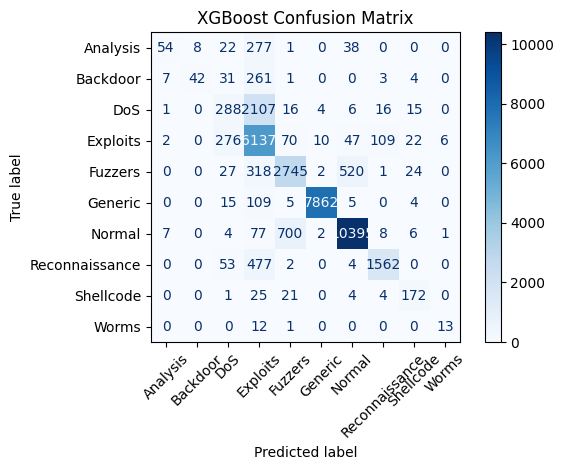

In [ ]:

from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

ConfusionMatrixDisplay.from_predictions(
    y_val,
    xgb_predictions,
    labels=label_encoder.classes_,
    xticks_rotation=45,
    cmap="Blues",
    values_format="d"
)

plt.title("XGBoost Confusion Matrix")
plt.tight_layout()
plt.show()


In [ ]:

from sklearn.utils.class_weight import compute_sample_weight

# Give greater weight to examples from underrepresented classes
sample_weights = compute_sample_weight(
    class_weight="balanced",
    y=y_train_encoded
)

print("Sample weights calculated:", len(sample_weights))
print("Minimum weight:", sample_weights.min())
print("Maximum weight:", sample_weights.max())


Sample weights calculated: 140272
Minimum weight: 0.31310714285714286
Maximum weight: 134.87692307692308


In [ ]:

xgb_weighted = XGBClassifier(
    n_estimators=300,
    max_depth=6,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="multi:softprob",
    num_class=len(label_encoder.classes_),
    eval_metric="mlogloss",
    tree_method="hist",
    random_state=42,
    n_jobs=-1
)

# Train using the sample weights
xgb_weighted.fit(
    X_train_xgb,
    y_train_encoded,
    sample_weight=sample_weights
)

print("Weighted XGBoost training completed!")


Weighted XGBoost training completed!


In [ ]:

weighted_predictions_encoded = xgb_weighted.predict(X_val_xgb)

weighted_predictions = label_encoder.inverse_transform(
    weighted_predictions_encoded.astype(int)
)

print("Accuracy:", accuracy_score(y_val, weighted_predictions))
print("Macro F1:", f1_score(y_val, weighted_predictions, average="macro"))
print("Weighted F1:", f1_score(y_val, weighted_predictions, average="weighted"))

print("\nClassification Report:\n")
print(classification_report(
    y_val,
    weighted_predictions,
    zero_division=0
))


Accuracy: 0.76403661353332
Macro F1: 0.6126090562946762
Weighted F1: 0.7964040846246552

Classification Report:

                precision    recall  f1-score   support

      Analysis       0.07      0.34      0.12       400
      Backdoor       0.04      0.27      0.07       349
           DoS       0.32      0.31      0.31      2453
      Exploits       0.89      0.51      0.65      6679
       Fuzzers       0.67      0.87      0.76      3637
       Generic       1.00      0.98      0.99      8000
        Normal       0.99      0.85      0.91     11200
Reconnaissance       0.84      0.80      0.82      2098
     Shellcode       0.54      0.94      0.68       227
         Worms       0.71      0.96      0.82        26

      accuracy                           0.76     35069
     macro avg       0.61      0.68      0.61     35069
  weighted avg       0.86      0.76      0.80     35069



In [ ]:

from sklearn.metrics import accuracy_score, f1_score
import pandas as pd

comparison = pd.DataFrame([
    {
        "Model": "Logistic Regression",
        "Accuracy": 0.6717,
        "Macro F1": 0.4100,
        "Weighted F1": 0.7200
    },
    {
        "Model": "Random Forest (Unweighted)",
        "Accuracy": 0.8235,
        "Macro F1": 0.5700,
        "Weighted F1": 0.8100
    },
    {
        "Model": "Random Forest (Weighted/Tuned)",
        "Accuracy": 0.7786,
        "Macro F1": 0.5894,
        "Weighted F1": None
    },
    {
        "Model": "XGBoost (Original)",
        "Accuracy": accuracy_score(y_val, xgb_predictions),
        "Macro F1": f1_score(y_val, xgb_predictions, average="macro"),
        "Weighted F1": f1_score(y_val, xgb_predictions, average="weighted")
    },
    {
        "Model": "XGBoost (Weighted)",
        "Accuracy": accuracy_score(y_val, weighted_predictions),
        "Macro F1": f1_score(y_val, weighted_predictions, average="macro"),
        "Weighted F1": f1_score(y_val, weighted_predictions, average="weighted")
    }
])

print(comparison.round(4).to_string(index=False))


                         Model  Accuracy  Macro F1  Weighted F1
           Logistic Regression    0.6717    0.4100       0.7200
    Random Forest (Unweighted)    0.8235    0.5700       0.8100
Random Forest (Weighted/Tuned)    0.7786    0.5894          NaN
            XGBoost (Original)    0.8346    0.6168       0.8174
            XGBoost (Weighted)    0.7640    0.6126       0.7964


In [ ]:

from google.colab import files

uploaded_test = files.upload()


Saving UNSW_NB15_testing-set.csv to UNSW_NB15_testing-set (1).csv


In [ ]:

import pandas as pd

test_df = pd.read_csv("UNSW_NB15_testing-set.csv")

print("Test dataset shape:", test_df.shape)
print("\nColumns:")
print(test_df.columns.tolist())

print("\nMissing values:", test_df.isnull().sum().sum())


Test dataset shape: (82332, 45)

Columns:
['id', 'dur', 'proto', 'service', 'state', 'spkts', 'dpkts', 'sbytes', 'dbytes', 'rate', 'sttl', 'dttl', 'sload', 'dload', 'sloss', 'dloss', 'sinpkt', 'dinpkt', 'sjit', 'djit', 'swin', 'stcpb', 'dtcpb', 'dwin', 'tcprtt', 'synack', 'ackdat', 'smean', 'dmean', 'trans_depth', 'response_body_len', 'ct_srv_src', 'ct_state_ttl', 'ct_dst_ltm', 'ct_src_dport_ltm', 'ct_dst_sport_ltm', 'ct_dst_src_ltm', 'is_ftp_login', 'ct_ftp_cmd', 'ct_flw_http_mthd', 'ct_src_ltm', 'ct_srv_dst', 'is_sm_ips_ports', 'attack_cat', 'label']

Missing values: 0


In [ ]:

# Separate test features and actual attack categories
y_test = test_df["attack_cat"]

X_test = test_df.drop(
    columns=["id", "attack_cat", "label"]
)

# Apply the SAME preprocessor fitted on training data
X_test_xgb = xgb_preprocessor.transform(X_test)

# Encode actual test labels using the existing encoder
y_test_encoded = label_encoder.transform(y_test)

print("Test features shape:", X_test_xgb.shape)
print("Test labels shape:", y_test_encoded.shape)
print("Test data prepared successfully!")


Test features shape: (82332, 194)
Test labels shape: (82332,)
Test data prepared successfully!


In [ ]:

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report
)

# Predict on the official test set
test_predictions_encoded = xgb_model.predict(X_test_xgb)

test_predictions = label_encoder.inverse_transform(
    test_predictions_encoded.astype(int)
)

print("TEST ACCURACY:",
      accuracy_score(y_test, test_predictions))

print("TEST MACRO F1:",
      f1_score(y_test, test_predictions, average="macro"))

print("TEST WEIGHTED F1:",
      f1_score(y_test, test_predictions, average="weighted"))

print("\nTEST CLASSIFICATION REPORT:\n")

print(classification_report(
    y_test,
    test_predictions,
    labels=label_encoder.classes_,
    zero_division=0
))


TEST ACCURACY: 0.7702351455084293
TEST MACRO F1: 0.5050606848903096
TEST WEIGHTED F1: 0.7818296862519504

TEST CLASSIFICATION REPORT:

                precision    recall  f1-score   support

      Analysis       0.01      0.02      0.02       677
      Backdoor       0.05      0.14      0.08       583
           DoS       0.61      0.09      0.16      4089
      Exploits       0.59      0.88      0.71     11132
       Fuzzers       0.32      0.60      0.42      6062
       Generic       1.00      0.97      0.98     18871
        Normal       0.97      0.76      0.85     37000
Reconnaissance       0.93      0.81      0.87      3496
     Shellcode       0.37      0.76      0.50       378
         Worms       0.63      0.39      0.48        44

      accuracy                           0.77     82332
     macro avg       0.55      0.54      0.51     82332
  weighted avg       0.84      0.77      0.78     82332



In [ ]:

import pandas as pd

class_counts = y_train.value_counts().sort_values()

print("Training examples per attack category:\n")
print(class_counts.to_string())

print("\nSmallest class:", class_counts.index[0])
print("Smallest class count:", class_counts.min())
print("Largest class:", class_counts.index[-1])
print("Largest class count:", class_counts.max())


Training examples per attack category:

attack_cat
Worms               104
Shellcode           906
Backdoor           1397
Analysis           1600
Reconnaissance     8393
DoS                9811
Fuzzers           14547
Exploits          26714
Generic           32000
Normal            44800

Smallest class: Worms
Smallest class count: 104
Largest class: Normal
Largest class count: 44800


In [ ]:

import numpy as np
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.metrics import accuracy_score, f1_score, classification_report

# Calculate class counts from the training labels only
class_counts = y_train_encoded.shape[0] / np.bincount(y_train_encoded)

# Moderate weights: inverse square root of class frequency
class_weights_moderate = 1 / np.sqrt(class_counts)

# Normalize weights so their average is approximately 1
class_weights_moderate = (
    class_weights_moderate / np.mean(class_weights_moderate)
)

# Assign each training example its class weight
sample_weights_moderate = class_weights_moderate[y_train_encoded]

print("Moderate sample weights calculated.")
print("Minimum:", sample_weights_moderate.min())
print("Maximum:", sample_weights_moderate.max())


Moderate sample weights calculated.
Minimum: 0.10375049679364841
Maximum: 2.153339575843166


In [ ]:

xgb_moderate = XGBClassifier(
    n_estimators=300,
    max_depth=6,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="multi:softprob",
    num_class=len(label_encoder.classes_),
    eval_metric="mlogloss",
    tree_method="hist",
    random_state=42,
    n_jobs=-1
)

xgb_moderate.fit(
    X_train_xgb,
    y_train_encoded,
    sample_weight=sample_weights_moderate
)

print("Moderately weighted XGBoost training completed!")


Moderately weighted XGBoost training completed!


In [ ]:

moderate_predictions_encoded = xgb_moderate.predict(X_val_xgb)

moderate_predictions = label_encoder.inverse_transform(
    moderate_predictions_encoded.astype(int)
)

print("Accuracy:",
      accuracy_score(y_val, moderate_predictions))

print("Macro F1:",
      f1_score(y_val, moderate_predictions, average="macro"))

print("Weighted F1:",
      f1_score(y_val, moderate_predictions, average="weighted"))

print("\nClassification Report:\n")
print(classification_report(
    y_val,
    moderate_predictions,
    zero_division=0
))


Accuracy: 0.8341270067581055
Macro F1: 0.5485823139364331
Weighted F1: 0.8066036856325746

Classification Report:

                precision    recall  f1-score   support

      Analysis       0.81      0.11      0.19       400
      Backdoor       0.88      0.10      0.18       349
           DoS       0.77      0.05      0.10      2453
      Exploits       0.61      0.97      0.75      6679
       Fuzzers       0.82      0.66      0.73      3637
       Generic       1.00      0.98      0.99      8000
        Normal       0.91      0.95      0.93     11200
Reconnaissance       0.95      0.71      0.81      2098
     Shellcode       0.81      0.56      0.66       227
         Worms       0.67      0.08      0.14        26

      accuracy                           0.83     35069
     macro avg       0.82      0.52      0.55     35069
  weighted avg       0.86      0.83      0.81     35069



In [ ]:

from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, f1_score
import pandas as pd

configs = [
    {"name": "XGB_A_depth4_lr01", "max_depth": 4,
     "learning_rate": 0.1, "n_estimators": 300},
    {"name": "XGB_B_depth6_lr005", "max_depth": 6,
     "learning_rate": 0.05, "n_estimators": 500},
    {"name": "XGB_C_depth8_lr005", "max_depth": 8,
     "learning_rate": 0.05, "n_estimators": 500}
]

tuned_xgb_models = {}
tuning_results = []

for config in configs:
    print("Training:", config["name"])

    model = XGBClassifier(
        n_estimators=config["n_estimators"],
        max_depth=config["max_depth"],
        learning_rate=config["learning_rate"],
        subsample=0.8,
        colsample_bytree=0.8,
        objective="multi:softprob",
        num_class=len(label_encoder.classes_),
        eval_metric="mlogloss",
        tree_method="hist",
        random_state=42,
        n_jobs=-1
    )

    model.fit(X_train_xgb, y_train_encoded)

    pred_encoded = model.predict(X_val_xgb)
    pred = label_encoder.inverse_transform(pred_encoded.astype(int))

    result = {
        "Model": config["name"],
        "Accuracy": accuracy_score(y_val, pred),
        "Macro F1": f1_score(y_val, pred, average="macro"),
        "Weighted F1": f1_score(y_val, pred, average="weighted")
    }

    tuning_results.append(result)
    tuned_xgb_models[config["name"]] = model

    print("Accuracy:", round(result["Accuracy"], 4))
    print("Macro F1:", round(result["Macro F1"], 4))
    print("Weighted F1:", round(result["Weighted F1"], 4))
    print("-" * 40)

tuning_df = pd.DataFrame(tuning_results)
print("\nTuning comparison:")
print(tuning_df.sort_values("Macro F1", ascending=False).to_string(index=False))


Training: XGB_A_depth4_lr01
Accuracy: 0.8311
Macro F1: 0.6039
Weighted F1: 0.8121
----------------------------------------
Training: XGB_B_depth6_lr005
Accuracy: 0.8349
Macro F1: 0.6134
Weighted F1: 0.8163
----------------------------------------
Training: XGB_C_depth8_lr005
Accuracy: 0.836
Macro F1: 0.6133
Weighted F1: 0.8202
----------------------------------------

Tuning comparison:
             Model  Accuracy  Macro F1  Weighted F1
XGB_B_depth6_lr005  0.834868  0.613376     0.816327
XGB_C_depth8_lr005  0.835952  0.613307     0.820190
 XGB_A_depth4_lr01  0.831076  0.603903     0.812074


In [ ]:

from sklearn.metrics import classification_report

best_tuned_xgb = tuned_xgb_models["XGB_B_depth6_lr005"]

tuned_predictions_encoded = best_tuned_xgb.predict(X_val_xgb)

tuned_predictions = label_encoder.inverse_transform(
    tuned_predictions_encoded.astype(int)
)

print(classification_report(
    y_val,
    tuned_predictions,
    zero_division=0
))


                precision    recall  f1-score   support

      Analysis       0.73      0.14      0.23       400
      Backdoor       0.85      0.13      0.22       349
           DoS       0.42      0.10      0.17      2453
      Exploits       0.62      0.93      0.75      6679
       Fuzzers       0.77      0.75      0.76      3637
       Generic       1.00      0.98      0.99      8000
        Normal       0.94      0.93      0.94     11200
Reconnaissance       0.92      0.74      0.82      2098
     Shellcode       0.69      0.77      0.73       227
         Worms       0.63      0.46      0.53        26

      accuracy                           0.83     35069
     macro avg       0.76      0.59      0.61     35069
  weighted avg       0.83      0.83      0.82     35069



Explainable AI-Based Network Intrusion Detection System — Progress Summary
1. Project objective
We are building an Explainable AI-Based Network Intrusion Detection System using Machine Learning.

The system aims to:
- Detect network traffic and classify it as normal or a particular type of attack.
- Use ML models to identify suspicious network activity.
- Use SHAP to explain why a model made a particular prediction.
- Eventually integrate the trained model into an application with prediction history, alerts, database storage, and a dashboard.
Our current stage: Dataset preparation and model training/evaluation are complete. We have selected an XGBoost model as our leading candidate. SHAP and application development are still pending.
2. Dataset selection and understanding
We used the UNSW-NB15 dataset, a network intrusion detection dataset containing normal network traffic and multiple attack categories.

We worked with two CSV files:
Dataset	Rows	Columns
Training dataset	175,341	45
Testing dataset	82,332	45

The dataset contains 10 target classes:
- Normal
- Generic
- Exploits
- Fuzzers
- DoS
- Reconnaissance
- Analysis
- Backdoor
- Shellcode
- Worms
Why did we use this dataset?

It provides labeled network traffic data, allowing us to train supervised ML models and evaluate their ability to recognize different attack types.
3. Data preprocessing
Before training, we separated the input features from the target variable.

Why did we remove these columns?
- attack_cat: This is the target we want the model to predict, so it cannot also be an input.
- label: It indicates normal versus attack traffic and could leak information about the target.
- id: It is an identifier rather than a meaningful network traffic feature.
We retained 42 input features.
Train-validation split
We split the training dataset into training and validation sets using an 80:20 ratio.

This produced:
Split	Rows
Training	140,272
Validation	35,069

Why?
- Training data teaches the model.
- Validation data helps us compare models and evaluate how well they generalize to unseen data.
- stratify=y preserves approximately the same class proportions in both splits.
4. Problems encountered during preprocessing
Problem A: Categorical features
Some inputs, such as proto, service, and state, are categorical rather than ordinary numerical values.

How we handled it: We used OneHotEncoder through a preprocessing pipeline to convert categorical values into numerical columns that XGBoost could process.

This creates additional columns, such as encoded protocol and service categories.
Problem B: Different target classes
The target contains text labels such as Normal, Generic, and DoS, while XGBoost's multiclass training requires numerical class labels.

How we handled it: We used LabelEncoder to encode the target labels as numbers and convert predictions back into readable class names.

We also used the fitted preprocessor to transform the validation data consistently with the training data.
5. Class imbalance
One of the most important issues we discovered was class imbalance.

Some categories have many more examples than others.
Attack category	Training examples
Normal	44,800
Generic	32,000
Exploits	26,714
Fuzzers	14,547
DoS	9,811
Reconnaissance	8,393
Analysis	1,600
Backdoor	1,397
Shellcode	906
Worms	104

Normal traffic has approximately 431 times as many training examples as Worms.
Why is this a problem?
A model can perform well on common classes while struggling to recognize rare attacks. Overall accuracy alone can hide this problem.
What did we try?
We experimented with different approaches, including class weighting and adjustments to the training data.

However, these experiments did not consistently improve our main evaluation metrics. Some improved the recognition of certain rare classes while reducing overall accuracy or performance on other classes.

Decision: We stopped experimenting with additional model configurations for now. We will document the limitations rather than continuing an endless tuning cycle.
6. Machine learning models tested
We evaluated several approaches.
Model / experiment	Validation accuracy	Validation macro F1
Logistic Regression	67.17%	~0.41
Random Forest, initial	82.35%	~0.57
Tuned weighted Random Forest	77.86%	0.5894
XGBoost, original	83.46%	0.6168
XGBoost, weighted	76.40%	0.6126
XGBoost, alternative configuration	83.60%	0.6133

Values are from our recorded experiments; small differences may arise from rounding.
Why did we try multiple models?
We wanted to establish a baseline, compare different algorithms, and see whether techniques for handling class imbalance improved attack detection.
What did we learn?
- Logistic Regression performed worse than our tree-based models.
- Random Forest produced strong overall results.
- XGBoost achieved the strongest recorded validation macro F1 among the main candidates.
- Class weighting did not automatically improve every metric.
- Increasing model complexity or changing hyperparameters did not produce a consistent, substantial improvement.
Our current choice: The original XGBoost model, xgb_model, remains our leading candidate based on its recorded validation macro F1. We are not claiming it is definitively the best possible model; we are simply freezing experiments and moving forward.
7. Understanding our evaluation metrics
We did not rely on accuracy alone.
Metric	What it tells us
Accuracy	Percentage of all predictions that were correct
Precision	When the model predicts a class, how often is it correct?
Recall	Of the actual examples of a class, how many did the model detect?
F1-score	Balance between precision and recall
Macro F1	Average F1 across classes, treating each class equally
Weighted F1	Average F1 weighted by the number of examples in each class

Why is macro F1 especially relevant?
Because rare attacks matter too. Macro F1 prevents common categories from dominating the evaluation as heavily as they do in accuracy and weighted F1.

For an intrusion detection system, missing a rare attack can be important even when overall accuracy looks good.
8. Final test-set evaluation
After selecting our leading candidate, we evaluated the original XGBoost model on the separate official test dataset.
Test accuracy
77.02%

Test macro F1
50.51%

Test weighted F1
78.18%

Validation accuracy
83.46%



Why is test accuracy lower than validation accuracy?
The validation split comes from the training file, whereas the official test set is separate and may differ in difficulty or class distribution.

The difference is approximately 6.44 percentage points.

This is worth investigating, but it does not automatically mean the model is useless. We should also check class-wise metrics and potential distribution differences.
What problems did the test report reveal?
The model performs very well on common classes such as Generic, but has low recall for some attack classes, including DoS, Analysis, and Backdoor.

That means it misses many examples of those attacks.

Honest conclusion: Our model is a reasonable starting point for a college project, but the current results are not sufficient to claim reliable real-world intrusion detection.

We must present these limitations honestly in the report.
9. Why we stopped model tuning
We spent time trying alternative models, weighting strategies, and hyperparameter configurations.

The improvements became inconsistent, and further experiments were taking us away from the project's main objective: building an explainable, usable system.

So we made a practical decision:
1. Keep the original XGBoost model as our leading candidate.
2. Preserve the evaluation metrics.
3. Stop adding more experimental configurations for now.
4. Move on to explainability and application development.

In [ ]:

!pip -q install shap

import shap
import numpy as np
import matplotlib.pyplot as plt

print("SHAP version:", shap.__version__)
print("XGBoost model:", type(xgb_model).__name__)
print("Validation data shape:", X_val_xgb.shape)


SHAP version: 0.54.1
XGBoost model: XGBClassifier
Validation data shape: (35069, 194)


In [ ]:


X_shap = X_val_xgb

# Convert sparse data to a dense array if necessary
if hasattr(X_shap, "toarray"):
    X_shap = X_shap.toarray()

# Get the encoded feature names
feature_names = xgb_preprocessor.get_feature_names_out()

# Create the SHAP explainer
explainer = shap.TreeExplainer(xgb_model)

# Calculate SHAP values
shap_values = explainer.shap_values(X_shap)

print("SHAP values calculated successfully!")
print("Input shape:", X_shap.shape)
print("Number of classes:", len(label_encoder.classes_))

if isinstance(shap_values, list):
    print("SHAP output: list of class-specific arrays")
    print("First class shape:", shap_values[0].shape)
else:
    print("SHAP output shape:", np.shape(shap_values))


SHAP values calculated successfully!
Input shape: (35069, 194)
Number of classes: 10
SHAP output shape: (35069, 194, 10)


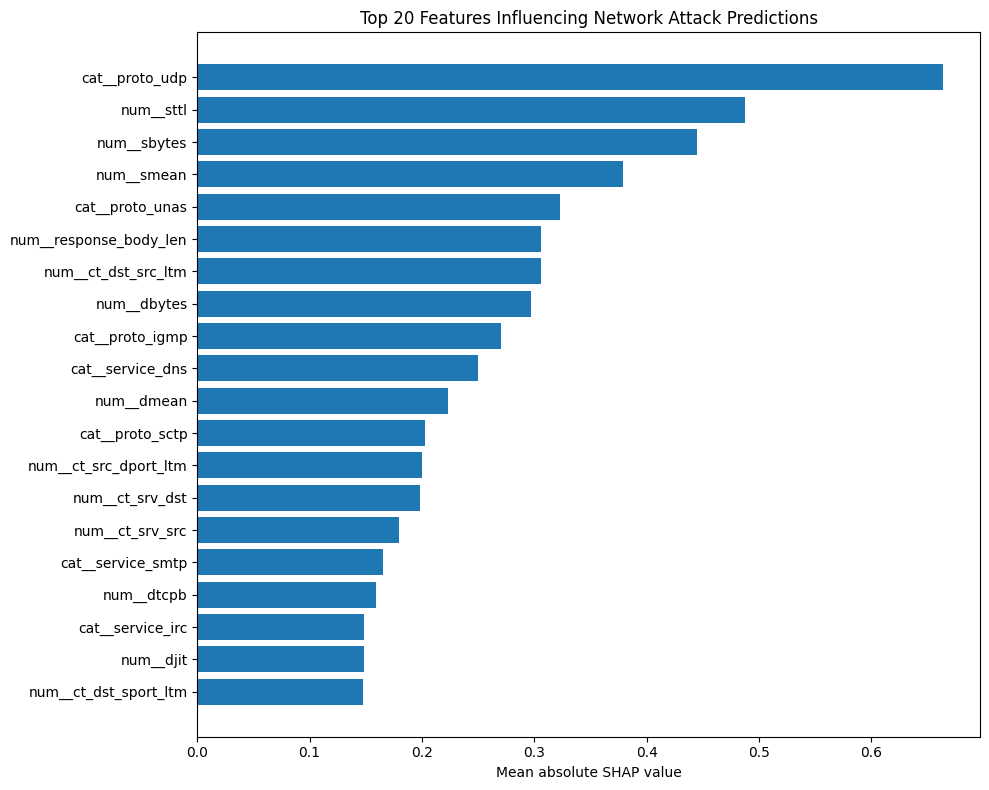

In [ ]:

# Average absolute SHAP importance across records and classes
global_importance = np.abs(shap_values).mean(axis=(0, 2))

# Get the top 20 features
top_indices = np.argsort(global_importance)[-20:]

plt.figure(figsize=(10, 8))
plt.barh(
    np.array(feature_names)[top_indices],
    global_importance[top_indices]
)
plt.xlabel("Mean absolute SHAP value")
plt.title("Top 20 Features Influencing Network Attack Predictions")
plt.tight_layout()
plt.show()


In [ ]:
print('shap_values' in globals())

True


In [ ]:
print("Model:", 'xgb_model' in globals())
print("Validation data:", 'X_val_xgb' in globals())
print("Feature names:", 'feature_names' in globals())
print("Label encoder:", 'label_encoder' in globals())

Model: True
Validation data: True
Feature names: True
Label encoder: True


In [ ]:

# Select one validation record
i = 0

# Get its actual and predicted classes
actual_class = y_val.iloc[i]
predicted_encoded = xgb_model.predict(X_val_xgb[i:i+1])[0]
predicted_class = label_encoder.inverse_transform(
    [int(predicted_encoded)]
)[0]

print("Actual class:", actual_class)
print("Predicted class:", predicted_class)


Actual class: Exploits
Predicted class: Exploits


In [ ]:

# Find the class index for Exploits
class_index = list(label_encoder.classes_).index(predicted_class)

# SHAP values for this record and predicted class
individual_shap = shap_values[i, :, class_index]

# Show the 10 most influential features
top_indices = np.argsort(np.abs(individual_shap))[-10:][::-1]

for idx in top_indices:
    print(
        f"{feature_names[idx]}: "
        f"SHAP = {individual_shap[idx]:.5f}"
    )


cat__proto_udp: SHAP = -1.02257
num__ct_srv_dst: SHAP = -0.63602
num__tcprtt: SHAP = -0.34088
num__ct_dst_src_ltm: SHAP = -0.31037
num__dttl: SHAP = -0.24752
num__sttl: SHAP = -0.24365
cat__service_radius: SHAP = 0.20671
cat__service_dhcp: SHAP = 0.20019
num__ct_srv_src: SHAP = -0.19095
num__ackdat: SHAP = -0.18577


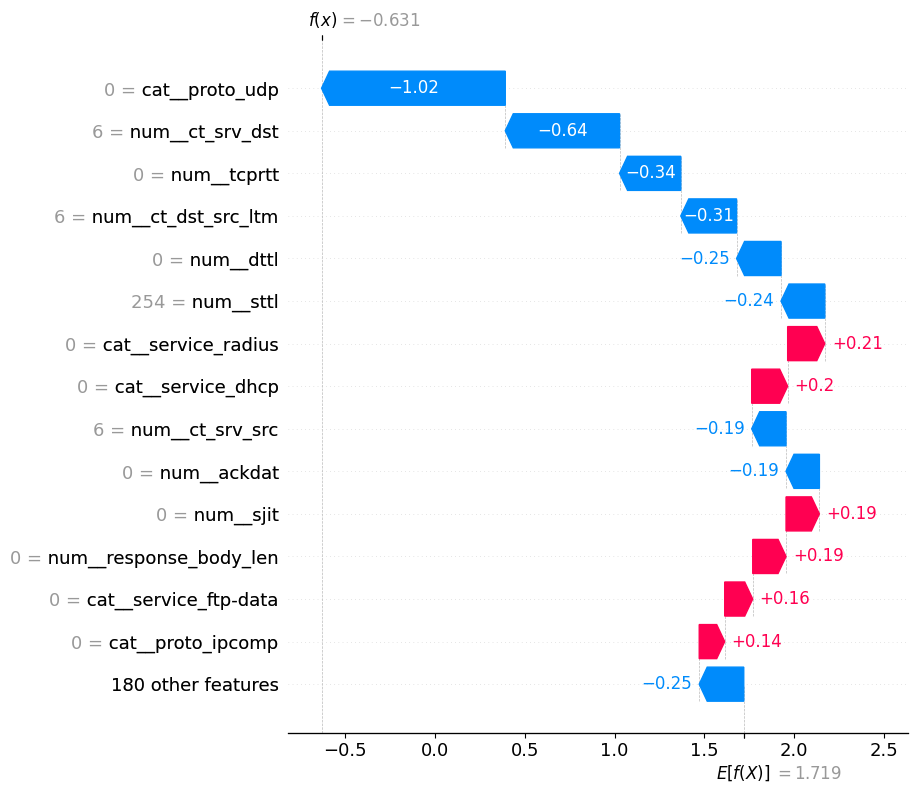

In [ ]:

# Explain the selected record for the predicted class
explanation = shap.Explanation(
    values=shap_values[i, :, class_index],
    base_values=explainer.expected_value[class_index],
    data=X_shap[i],
    feature_names=feature_names
)

shap.plots.waterfall(explanation, max_display=15)


In [ ]:

from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [ ]:

import os
import joblib
import numpy as np

save_dir = "/content/drive/MyDrive/Network_IDS"
os.makedirs(save_dir, exist_ok=True)

# 1. Save the trained model and preprocessing objects
joblib.dump(xgb_model, f"{save_dir}/xgb_model.joblib")
joblib.dump(xgb_preprocessor, f"{save_dir}/preprocessor.joblib")
joblib.dump(label_encoder, f"{save_dir}/label_encoder.joblib")

# 2. Save feature names and global importance
np.save(f"{save_dir}/feature_names.npy", feature_names)
np.save(f"{save_dir}/global_importance.npy", global_importance)

# 3. Save the individual Exploits explanation
np.save(f"{save_dir}/individual_shap.npy", individual_shap)

# 4. Save SHAP values for the selected record
np.save(f"{save_dir}/selected_record.npy", X_shap[i])

print("Saved artifacts to:", save_dir)
print("Files:", os.listdir(save_dir))


Saved artifacts to: /content/drive/MyDrive/Network_IDS
Files: ['xgb_model.joblib', 'preprocessor.joblib', 'label_encoder.joblib', 'feature_names.npy', 'global_importance.npy', 'individual_shap.npy', 'selected_record.npy']


# Explainable AI-Based Network Intrusion Detection System
## Project Progress Report

### 1. Project Objective
To develop a machine-learning-based Network Intrusion Detection System (NIDS) that classifies network traffic into normal traffic and different attack categories, with SHAP-based explanations to improve interpretability.

### 2. Work Completed

**Phase 1: Dataset Preparation**
- Used the UNSW-NB15 training and testing datasets.
- Removed unnecessary identifier and target-leakage columns (`id`, `label`).
- Separated input features from the target variable, `attack_cat`.
- Applied an 80:20 stratified training-validation split.
- Used one-hot encoding for categorical features and label encoding for target classes.

**Phase 2: Model Training and Evaluation**
- Experimented with Logistic Regression, Random Forest, and XGBoost.
- Explored class imbalance handling and alternative model configurations.
- Selected the original XGBoost model as the current leading candidate.
- Evaluated it on the official test dataset.

Key results:
- Validation accuracy: **83.46%**
- Test accuracy: **77.02%**
- Test macro F1-score: **50.51%**
- Test weighted F1-score: **78.18%**

The evaluation revealed that the model performs well on common categories but struggles with certain rare attack classes.

**Phase 3: Explainable AI Using SHAP**
- Calculated SHAP values for all 35,069 validation records across 194 encoded features and 10 classes.
- Generated a global feature-importance visualization.
- Examined an individual prediction correctly classified as `Exploits`.
- Generated a SHAP waterfall plot to visualize individual feature contributions.

**Phase 4: Saving Project Artifacts**
- Saved the trained XGBoost model, preprocessing pipeline, and label encoder to Google Drive.
- Saved feature names, global feature importance, and the selected record's SHAP explanation.
- Saved the Colab notebook.

### 3. Challenges Faced
- Categorical features required encoding before model training.
- Severe class imbalance affected the detection of rare attacks.
- Test performance was lower than validation performance.
- Colab runtime disconnections risked losing variables and requiring repeated computation.

These challenges were addressed through preprocessing, model comparison, separate test evaluation, SHAP explainability, and saving project artifacts to Google Drive.

### 4. Current Status
Dataset preparation, model experimentation, evaluation, core SHAP analysis, and artifact saving are complete.

The model remains a prototype and requires further validation before any real-world security deployment.

### 5. Next Steps
1. Build the backend prediction API using the saved model and preprocessing pipeline.
2. Integrate SHAP explanations into the API.
3. Store predictions and their details in a database.
4. Implement attack alerts and prediction history.
5. Develop a dashboard for predictions, explanations, and monitoring.
6. Test the complete application and document its limitations.
